### Prof. Alfio Ferrara

# Regole e apprendimento

##  Metodologie informatiche nelle discipline umanistiche
##### A.A. 2026/2027

---

Nel notebook precedente abbiamo giocato a Frozen Lake e ne abbiamo scritto le regole. Ora lasciamo giocare un programma al nostro posto e ci chiediamo come possa decidere cosa fare.

## Un agente sul lago

Il lago è una griglia 5×5. L'agente parte in alto a sinistra e deve raggiungere il quadrato verde, evitando i buchi neri. Ha un numero limitato di mosse.

L'agente **non vede la mappa**. Prima di ogni mossa sa soltanto:

- cosa c'è nelle quattro celle adiacenti (libera, buco, bordo, traguardo);
- quante volte è già stato in ognuna di quelle celle, perché tiene un taccuino;
- in che direzione si trova il traguardo (la bussola).

Con queste informazioni una funzione, `choose_action`, decide la mossa. La funzione sta nel file `nlp/lake_rules.py`. Per ora contiene una regola provvisoria.

In [ ]:
%load_ext autoreload
%autoreload 2

In [5]:
from nlp.lake_agent import run, evaluate, Lake
from nlp.lake_rules import choose_action_go_right, choose_action_random, choose_action_free_view, choose_action_free_memory

In [6]:
lake = Lake(width=10, height=10, holes=[(2, 2), (3, 7), (8, 9)])

## Una partita

Facciamo giocare l'agente una volta. Il triangolo rosso è l'agente, il numero grigio in ogni cella dice quante volte c'è passato.

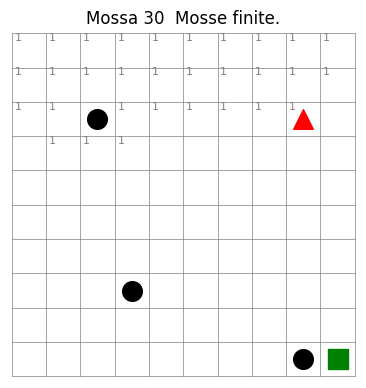

In [7]:
run(choose_action_free_memory, delay=0.1, max_moves=30, lake=lake)

## Cosa riceve la funzione

Rifacciamo la partita, più lentamente, e a ogni mossa stampiamo le informazioni che arrivano a `choose_action` e la scelta che ne esce.

In [ ]:
run(choose_action_go_right, delay=1.5, show_inputs=True, max_moves=4)

## Molte partite

Una sola partita non basta per giudicare una regola. Facciamo giocare l'agente tante volte e guardiamo come finiscono le partite.

In [8]:
results = evaluate(choose_action_free_memory, episodes=1000, max_moves=150, lake=lake)

labels = {"reached": "traguardo raggiunto", "fell": "caduto in un buco", "timeout": "mosse finite"}
for status, share in results.items():
    print(f"{labels[status]:<22}{share:>6.1%}")

traguardo raggiunto   100.0%
caduto in un buco       0.0%
mosse finite            0.0%


## Un momento di riflessione

- Cosa sa l'agente del lago e cosa non sa? Chi ha deciso cosa mostrargli?
- La regola provvisoria dice sempre la stessa cosa. Quali delle informazioni che riceve non usa?
- Quante partite servono per fidarci della percentuale? Se la regola è casuale, due prove danno lo stesso numero?
- Come scriveremmo una regola che porta l'agente al traguardo? E come ci accorgiamo se è migliore di un'altra?

## Un agente che impara

Finora la regola l'abbiamo scritta noi. Proviamo a far fare all'agente un'altra cosa: giocare, vedere cosa succede e correggersi.

L'agente non ha più una regola ma una **tabella**. Per ogni situazione che incontra la tabella contiene un valore per ciascuna delle quattro mosse. Dopo ogni mossa il lago restituisce un **premio** e il valore della mossa appena fatta viene corretto.

Il comportamento dell'agente è fatto di quattro funzioni, nel file `nlp/lake_learning_rules.py`, come le regole stavano in `nlp/lake_rules.py`:

- `features`: di tutto ciò che l'agente percepisce, cosa tiene per riconoscere una situazione (lo *stato*);
- `reward`: il premio dopo ogni mossa (`+1` al traguardo, `-1` in un buco, `-0.01` altrimenti);
- `choose_...`: come sceglie la mossa guardando la tabella (`epsilon` è la quota di mosse casuali, per provare strade nuove);
- `learn_...`: come corregge la tabella dopo la mossa. `learn_q` avvicina il valore al premio più il valore della migliore mossa successiva.

`LearningAgent` mette insieme le quattro funzioni e la tabella. Per cambiare criterio si modifica una funzione, oppure se ne scrive un'altra e la si passa all'agente.

In [ ]:
from nlp.lake_learning import LearningAgent, train, greedy, plot_learning, show_values
from nlp.lake_learning_rules import (
    features, features_with_notebook, reward,
    choose_greedy, choose_epsilon_greedy, choose_random,
    learn_q, learn_immediate,
)

## Prima di imparare

Creiamo l'agente. La tabella è vuota: tutti i valori sono 0, quindi la scelta è casuale. Usiamo `greedy`, che ne blocca le mosse casuali, per vedere cosa sa fare con ciò che ha imparato (per ora niente).

In [ ]:
agent = LearningAgent()
results = evaluate(greedy(agent), episodes=1000)
for status, share in results.items():
    print(f"{labels[status]:<22}{share:>6.1%}")

## Imparare giocando

Facciamo giocare l'agente 500 partite. Dopo ognuna la tabella si è aggiornata. Il grafico mostra, ogni 20 partite, quante finiscono al traguardo.

In [ ]:
outcomes = train(agent, episodes=500)
plot_learning(outcomes, window=20)

## Dopo aver imparato

Rifacciamo la misura di prima, sulle stesse 1000 partite, e poi guardiamo la tabella.

In [ ]:
results = evaluate(greedy(agent), episodes=1000)
for status, share in results.items():
    print(f"{labels[status]:<22}{share:>6.1%}")

In [ ]:
print(f"Situazioni incontrate: {len(agent.values)}")
show_values(agent, limit=6)

## Guardiamolo giocare

Ora la partita con l'agente che ha imparato. Anche qui blocchiamo le mosse casuali.

In [ ]:
run(greedy(agent), delay=0.3, show_inputs=True)

## Un momento di riflessione

- Chi ha scritto la regola che l'agente usa adesso? Dove si trova, e possiamo leggerla come leggiamo `choose_action_free_view`?
- Durante l'apprendimento il grafico non arriva a 100%, mentre dopo sì. Perché? Cosa cambia se mettiamo `EPSILON = 0` fin dall'inizio?
- L'agente ha incontrato poche situazioni, perché non conosce la posizione ma solo ciò che vede. Se la bussola non ci fosse, cosa imparerebbe? E se il lago cambiasse (altri buchi)?
- Chi ha deciso i premi? Cosa imparerebbe l'agente se cadere nel buco costasse come una mossa normale?
- Questo è apprendimento: cosa c'è di diverso, e cosa di uguale, rispetto a una regola scritta a mano?

## Da fare in aula

Cambiamo una funzione alla volta e rimisuriamo con `train` ed `evaluate(greedy(agent))`:

- `features_with_notebook` al posto di `features`: `LearningAgent(features=features_with_notebook)`;
- `learn_immediate` al posto di `learn_q`: `LearningAgent(learn=learn_immediate)`;
- una `reward` diversa, una `choose_...` nuova, i valori di `EPSILON`, `ALPHA`, `GAMMA`;
- un lago diverso: `train(agent, lake=Lake(holes=...))`.